## 05 - Avaliação final do modelo

Após a etapa de comparação e ajuste de hiperparâmetros, a Random Forest multivariada otimizada foi selecionada como modelo principal para a avaliação final.

Neste notebook, o modelo será treinado utilizando todo o conjunto de treino disponível e posteriormente avaliado no conjunto de teste final, que permaneceu preservado durante as etapas anteriores de seleção e ajuste.

A avaliação será realizada por meio das métricas MAE e RMSE, além de análises gráficas entre os valores observados e previstos de precipitação diária.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Hiperparâmetros selecionados no notebook 04 com a base local
PARAMETROS_RF_SP = {
    "n_estimators": 100,
    "min_samples_split": 20,
    "min_samples_leaf": 10,
    "max_features": "sqrt",
    "max_depth": 10,
    "random_state": 42,
    "n_jobs": -1,
}
print("Configuração da Random Forest:", PARAMETROS_RF_SP)

Configuração da Random Forest: {'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10, 'random_state': 42, 'n_jobs': -1}


### Preparação da base para avaliação final

Para garantir a reprodutibilidade da avaliação, a base diária é carregada novamente e são reconstruídas as mesmas variáveis utilizadas durante a etapa de modelagem.

A separação cronológica de 80% para treino e 20% para teste é reproduzida exatamente como no notebook anterior. O conjunto de teste permanece reservado exclusivamente para esta etapa de avaliação final.

In [2]:
import pandas as pd
import numpy as np

# Carrega a base diária
df = pd.read_parquet(
    "../data/gold/a701_2010_2025_diario_horario_sp.parquet"
)

# Garante formato de data
df["DATA (YYYY-MM-DD)"] = pd.to_datetime(
    df["DATA (YYYY-MM-DD)"]
)

# Variáveis de calendário
df["mes"] = df["DATA (YYYY-MM-DD)"].dt.month
df["dia_ano"] = df["DATA (YYYY-MM-DD)"].dt.dayofyear

df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)

df["dia_ano_sin"] = np.sin(
    2 * np.pi * df["dia_ano"] / 365.25
)

df["dia_ano_cos"] = np.cos(
    2 * np.pi * df["dia_ano"] / 365.25
)

# Lags de precipitação
df["precipitacao_lag_1"] = (
    df["precipitacao_diaria_mm"].shift(1)
)

df["precipitacao_lag_2"] = (
    df["precipitacao_diaria_mm"].shift(2)
)

df["precipitacao_lag_3"] = (
    df["precipitacao_diaria_mm"].shift(3)
)

# Médias móveis usando somente informações anteriores
df["media_movel_3"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(3)
    .mean()
)

df["media_movel_7"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(7)
    .mean()
)

# Variáveis meteorológicas defasadas em 1 dia
df["temperatura_lag_1"] = (
    df["temperatura_media"].shift(1)
)

df["umidade_lag_1"] = (
    df["umidade_media"].shift(1)
)

df["pressao_lag_1"] = (
    df["pressao_media"].shift(1)
)

df["vento_lag_1"] = (
    df["vento_medio"].shift(1)
)

print("Dimensão da base:", df.shape)
print("Período:", df["DATA (YYYY-MM-DD)"].min(), "até", df["DATA (YYYY-MM-DD)"].max())
# Assegurar um dia por linha em ordem cronológica antes de criar os lags
assert df["DATA (YYYY-MM-DD)"].is_monotonic_increasing, "Datas fora de ordem"
assert not df["DATA (YYYY-MM-DD)"].duplicated().any(), "Datas diárias duplicadas"
assert df["DATA (YYYY-MM-DD)"].diff().dropna().eq(pd.Timedelta(days=1)).all(), "Há datas ausentes no calendário antes dos lags"


Dimensão da base: (5844, 29)
Período: 2010-01-01 00:00:00 até 2025-12-31 00:00:00


In [3]:
features_multivariadas = [
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7",
    "temperatura_lag_1",
    "umidade_lag_1",
    "pressao_lag_1",
    "vento_lag_1"
]

alvo = "precipitacao_diaria_mm"

base_modelagem = df[
    ["DATA (YYYY-MM-DD)", alvo] + features_multivariadas
].dropna().copy().reset_index(drop=True)

print("Registros válidos:", len(base_modelagem))
print(
    "Período:",
    base_modelagem["DATA (YYYY-MM-DD)"].min(),
    "até",
    base_modelagem["DATA (YYYY-MM-DD)"].max()
)

base_modelagem.head()


Registros válidos: 4953
Período: 2010-01-08 00:00:00 até 2025-12-21 00:00:00


,DATA (YYYY-MM-DD),precipitacao_diaria_mm,mes_sin,mes_cos,dia_ano_sin,dia_ano_cos,precipitacao_lag_1,precipitacao_lag_2,precipitacao_lag_3,media_movel_3,media_movel_7,temperatura_lag_1,umidade_lag_1,pressao_lag_1,vento_lag_1
0,2010-01-08,30.2,0.5,0.866025,0.137185,0.990545,0.2,8.0,50.2,19.466667,16.428571,23.304167,78.583333,922.725000,2.145833
1,2010-01-09,0.2,0.5,0.866025,0.154204,0.988039,30.2,0.2,8.0,12.800000,19.828571,22.641667,85.625000,924.825000,1.662500
2,2010-01-10,0.6,0.5,0.866025,0.171177,0.985240,0.2,30.2,0.2,10.200000,14.657143,24.458333,73.958333,925.237500,1.783333
3,2010-01-11,29.2,0.5,0.866025,0.188099,0.982150,0.6,0.2,30.2,10.333333,14.685714,26.329167,65.083333,924.158333,2.579167
4,2010-01-12,2.8,0.5,0.866025,0.204966,0.978769,29.2,0.6,0.2,10.000000,16.942857,25.191667,67.250000,923.795833,1.850000


In [4]:
indice_corte = int(len(base_modelagem) * 0.8)

treino = base_modelagem.iloc[:indice_corte].copy()
teste = base_modelagem.iloc[indice_corte:].copy()

print("Total:", len(base_modelagem))

print(
    "Treino:",
    len(treino),
    "|",
    treino["DATA (YYYY-MM-DD)"].min(),
    "até",
    treino["DATA (YYYY-MM-DD)"].max()
)

print(
    "Teste:",
    len(teste),
    "|",
    teste["DATA (YYYY-MM-DD)"].min(),
    "até",
    teste["DATA (YYYY-MM-DD)"].max()
)
assert treino["DATA (YYYY-MM-DD)"].max() < teste["DATA (YYYY-MM-DD)"].min(), "Treino e teste se sobrepõem temporalmente"


Total: 4953
Treino: 3962 | 2010-01-08 00:00:00 até 2022-01-11 00:00:00
Teste: 991 | 2022-01-12 00:00:00 até 2025-12-21 00:00:00


In [5]:
X_train = treino[features_multivariadas].copy()
X_test = teste[features_multivariadas].copy()

y_train = treino[alvo].copy()
y_test = teste[alvo].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3962, 13)
X_test: (991, 13)
y_train: (3962,)
y_test: (991,)


## Treinamento do modelo selecionado

A Random Forest é reconstruída com os **parâmetros escolhidos no notebook 04 com a base local** (`n_estimators=100`, `min_samples_split=20`, `min_samples_leaf=10`, `max_features="sqrt"`, `max_depth=10`). O ajuste usa exclusivamente os dados de treinamento (80% inicial). Nenhuma observação do teste entra no treinamento.

In [6]:
modelo_final = RandomForestRegressor(**PARAMETROS_RF_SP)
modelo_final.fit(X_train, y_train)
print("Modelo treinado com sucesso.")

Modelo treinado com sucesso.


### Avaliação no conjunto de teste final

Com o modelo treinado utilizando todo o conjunto de treino, são realizadas as previsões para o conjunto de teste final.

Esse conjunto corresponde aos 20% finais da série temporal e permaneceu preservado durante as etapas de comparação entre modelos e ajuste de hiperparâmetros.

O desempenho final é avaliado pelas métricas MAE e RMSE.

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred_final = modelo_final.predict(X_test)

mae_final = mean_absolute_error(
    y_test,
    y_pred_final
)

rmse_final = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_final
    )
)

print(f"MAE final: {mae_final:.3f} mm")
print(f"RMSE final: {rmse_final:.3f} mm")

MAE final: 5.251 mm
RMSE final: 9.217 mm


#### Resultado da avaliação final

No conjunto de teste final, a Random Forest multivariada otimizada apresentou **MAE de 5,251 mm** e **RMSE de 9,217 mm**.

Os valores obtidos foram inferiores às médias observadas durante a validação temporal, em que o modelo apresentou MAE de **5,497 mm** e RMSE de **10,175 mm**.

Esse resultado indica que o modelo manteve bom desempenho ao ser aplicado a um período futuro não utilizado nas etapas de seleção e ajuste, sugerindo capacidade adequada de generalização para os dados avaliados.

A diferença entre MAE e RMSE também indica a presença de alguns erros de maior magnitude, característica esperada em séries de precipitação diária devido à ocorrência de eventos intensos e menos frequentes.

### Comparação entre valores observados e previstos

Para complementar a avaliação numérica, os valores observados de precipitação diária são comparados com as previsões produzidas pela Random Forest no conjunto de teste final.

Essa visualização permite avaliar não apenas o erro médio do modelo, mas também seu comportamento em dias com baixa, moderada e alta precipitação.

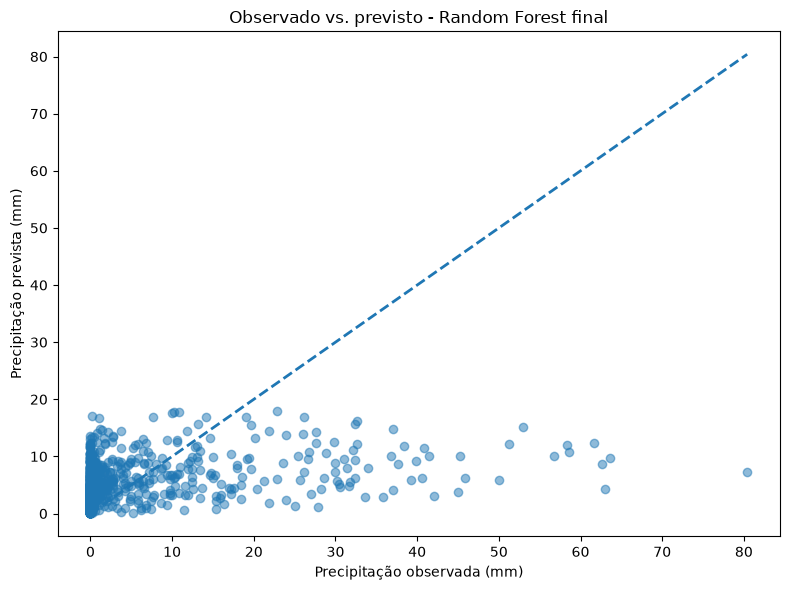

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_final,
    alpha=0.5
)

limite_max = max(
    y_test.max(),
    y_pred_final.max()
)

plt.plot(
    [0, limite_max],
    [0, limite_max],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Precipitação observada (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Observado vs. previsto - Random Forest final")

plt.tight_layout()
plt.show()

A dispersão entre precipitação observada e prevista permite investigar a **tendência a valores intermediários**, a presença de previsões positivas em dias secos e a eventual **subestimação de eventos intensos**. Essas hipóteses devem ser confirmadas pelo gráfico produzido nesta nova execução; não se devem repetir interpretações específicas da versão UTC sem conferência.

### Evolução temporal das previsões

Além da comparação direta entre valores observados e previstos, é importante avaliar o comportamento do modelo ao longo do tempo.

O gráfico a seguir apresenta a precipitação observada e a precipitação prevista pela Random Forest no período correspondente ao conjunto de teste final.

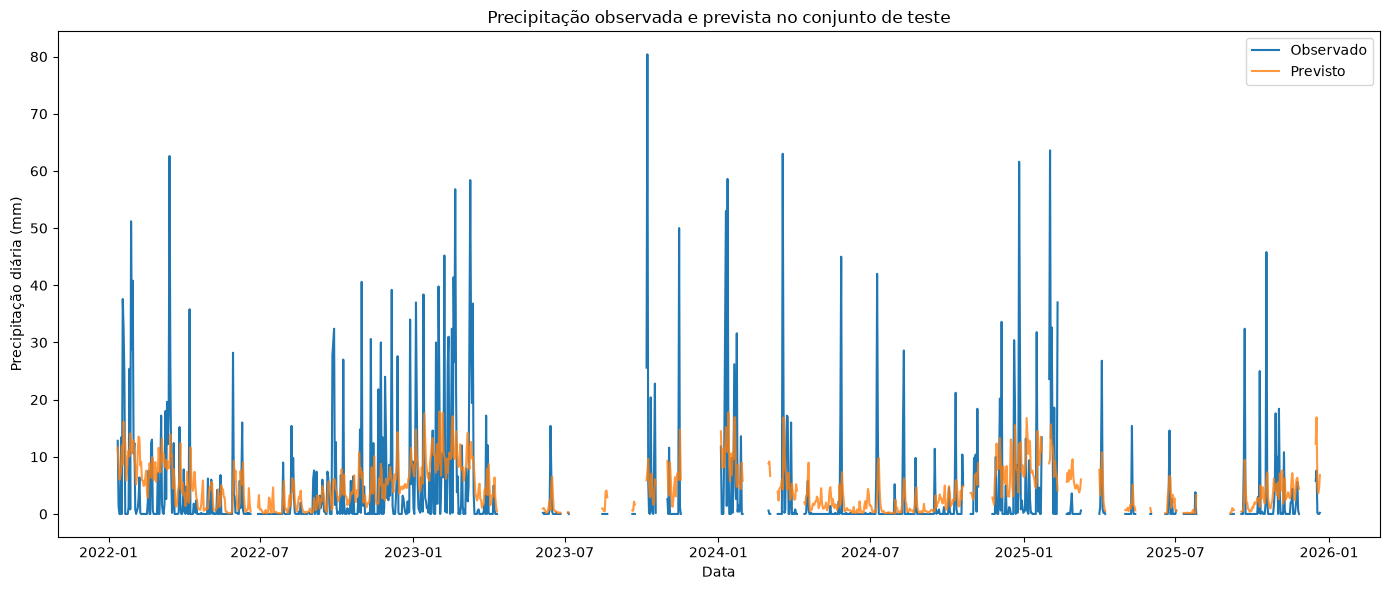

In [9]:
# DataFrame com observado e previsto
resultado_teste = pd.DataFrame({
    "data": teste["DATA (YYYY-MM-DD)"].values,
    "observado": y_test.values,
    "previsto": y_pred_final
})

# Define a data como índice
resultado_teste = resultado_teste.set_index("data")

# Cria uma sequência diária completa
datas_completas = pd.date_range(
    start=resultado_teste.index.min(),
    end=resultado_teste.index.max(),
    freq="D"
)

# Reindexa, criando NaN nos dias ausentes
resultado_teste = resultado_teste.reindex(datas_completas)

# Gráfico corrigido
plt.figure(figsize=(14, 6))

plt.plot(
    resultado_teste.index,
    resultado_teste["observado"],
    label="Observado",
    linewidth=1.5
)

plt.plot(
    resultado_teste.index,
    resultado_teste["previsto"],
    label="Previsto",
    linewidth=1.5,
    alpha=0.8
)

plt.xlabel("Data")
plt.ylabel("Precipitação diária (mm)")
plt.title("Precipitação observada e prevista no conjunto de teste")
plt.legend()

plt.tight_layout()
plt.show()

O gráfico temporal preserva as **lacunas entre datas sem registros modeláveis** por meio de `reindex` em um calendário diário. Observe se as previsões acompanham a variabilidade temporal e se as maiores chuvas são subestimadas. As conclusões devem se basear no novo gráfico, não nos resultados da versão UTC.

## Erros por faixa de precipitação

Para compreender o comportamento do modelo em diferentes intensidades, a avaliação é estratificada pelo acumulado **observado**. São utilizadas as faixas: 0 mm, acima de 0 até 5 mm, acima de 5 até 20 mm, acima de 20 até 50 mm e acima de 50 mm. As métricas e quantidades de dias serão calculadas novamente a partir das novas previsões.

In [10]:
resultado_faixas = pd.DataFrame({
    "observado": y_test.to_numpy(),
    "previsto": y_pred_final,
})
resultado_faixas["faixa_precipitacao"] = pd.cut(
    resultado_faixas["observado"],
    bins=[-0.001, 0, 5, 20, 50, np.inf],
    labels=["0 mm", ">0 a 5 mm", ">5 a 20 mm", ">20 a 50 mm", ">50 mm"],
)
resultado_faixas["erro_abs"] = (
    resultado_faixas["observado"] - resultado_faixas["previsto"]
).abs()
resultado_faixas["erro_quad"] = (
    resultado_faixas["observado"] - resultado_faixas["previsto"]
) ** 2

analise_faixas = (
    resultado_faixas
    .groupby("faixa_precipitacao", observed=True)
    .agg(
        n_dias=("observado", "size"),
        media_observada_mm=("observado", "mean"),
        media_prevista_mm=("previsto", "mean"),
        MAE_mm=("erro_abs", "mean"),
        MSE_mm=("erro_quad", "mean"),
    )
    .reset_index()
)
analise_faixas["RMSE_mm"] = np.sqrt(analise_faixas.pop("MSE_mm"))
assert int(analise_faixas["n_dias"].sum()) == len(y_test)
display(analise_faixas.round(2))

,faixa_precipitacao,n_dias,media_observada_mm,media_prevista_mm,MAE_mm,RMSE_mm
0,0 mm,572,0.00,2.85,2.85,4.03
1,>0 a 5 mm,229,1.41,5.79,4.56,5.70
2,>5 a 20 mm,121,10.89,7.09,5.55,6.77
3,>20 a 50 mm,59,31.31,8.37,22.94,24.46
4,>50 mm,10,60.92,10.24,50.68,51.59


A análise por faixa de precipitação evidencia que o desempenho do modelo varia substancialmente conforme a intensidade dos eventos.

Nos dias sem precipitação, que representam a maior parcela do conjunto de teste, o modelo apresentou erro relativamente reduzido, embora tenha produzido previsões positivas mesmo quando o acumulado observado foi igual a zero. Para eventos de baixa e moderada intensidade, os erros permaneceram menores em comparação com os eventos intensos.

Entretanto, ocorreu aumento expressivo dos erros nos eventos de maior intensidade. Para dias com precipitação observada acima de 20 mm e até 50 mm, o acumulado médio observado foi de **31,31 mm**, enquanto a previsão média foi de apenas **8,37 mm**, resultando em MAE de **22,94 mm**. Nos eventos acima de 50 mm, a precipitação média observada foi de **60,92 mm**, enquanto a previsão média foi de **10,24 mm**, com MAE de **50,68 mm**.

Os resultados evidenciam uma tendência de subestimação dos eventos intensos. Dessa forma, embora as métricas globais sintetizem o desempenho do modelo, sua interpretação deve considerar a predominância de dias secos ou com baixa precipitação na base. O modelo apresenta erros menores nas condições mais frequentes, mas possui limitações importantes na estimativa da magnitude de chuvas intensas.

Cabe destacar que a faixa acima de 50 mm contém apenas **10 observações**, exigindo cautela na generalização dos resultados para eventos extremos.

### Comparação entre precipitação média observada e prevista por faixa

Para complementar a análise por faixa de precipitação, foi construída uma visualização comparando a média observada e a média prevista pelo modelo em cada grupo de intensidade de chuva.

Esse gráfico permite identificar com maior clareza se o modelo tende a superestimar ou subestimar determinadas faixas de precipitação.

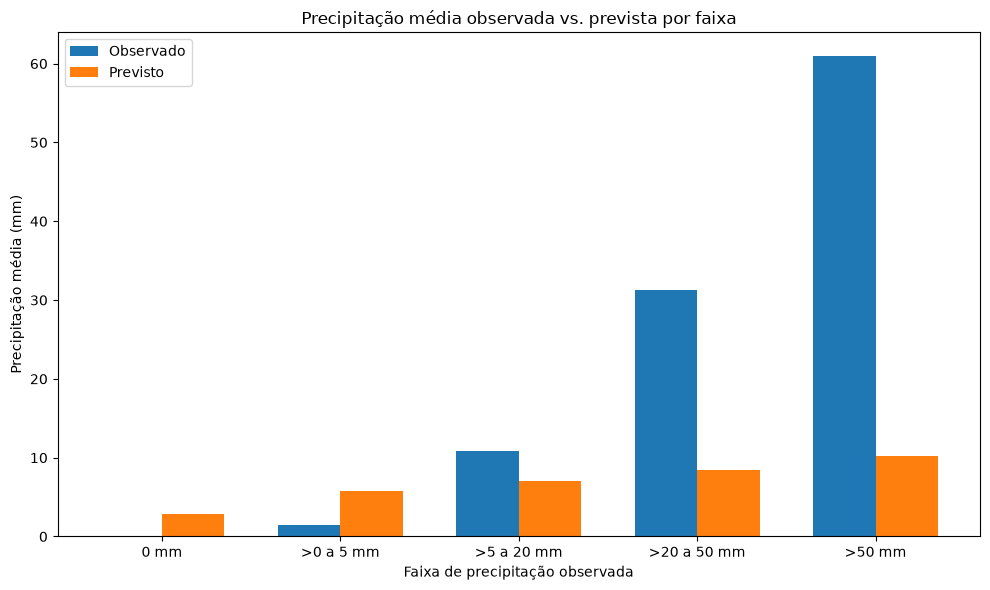

In [13]:
faixas = analise_faixas["faixa_precipitacao"].astype(str)
x = np.arange(len(faixas))
largura = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - largura/2,
    analise_faixas["media_observada_mm"],
    width=largura,
    label="Observado"
)

plt.bar(
    x + largura/2,
    analise_faixas["media_prevista_mm"],
    width=largura,
    label="Previsto"
)

plt.xticks(x, faixas)
plt.xlabel("Faixa de precipitação observada")
plt.ylabel("Precipitação média (mm)")
plt.title("Precipitação média observada vs. prevista por faixa")
plt.legend()

plt.tight_layout()
plt.show()

O gráfico confirma que o comportamento do modelo varia de acordo com a intensidade da precipitação observada. Nos dias sem chuva e nos eventos de baixa intensidade, as previsões se mantêm relativamente próximas, embora ainda ocorram previsões positivas em dias sem precipitação.

À medida que a intensidade observada aumenta, torna-se evidente a tendência de subestimação. Nas faixas de maior precipitação, a média prevista permanece muito abaixo da média observada, indicando que o modelo possui maior dificuldade para representar adequadamente os eventos intensos.

Esse resultado reforça a interpretação de que o modelo consegue descrever de forma mais satisfatória o comportamento predominante da série, mas apresenta limitação importante na previsão da magnitude das chuvas mais fortes.O gráfico contrapõe os acumulados médios **observados e previstos por faixa**. Verifique quais faixas apresentam superestimação ou subestimação na versão corrigida e evite transferir valores ou interpretações quantitativas da base UTC.

### Erro absoluto médio por faixa de precipitação

Para avaliar como o erro do modelo se comporta em diferentes intensidades de chuva, foi analisado o MAE em cada faixa de precipitação observada.

Essa comparação permite verificar se o erro permanece aproximadamente constante ou se aumenta à medida que os eventos se tornam mais intensos.

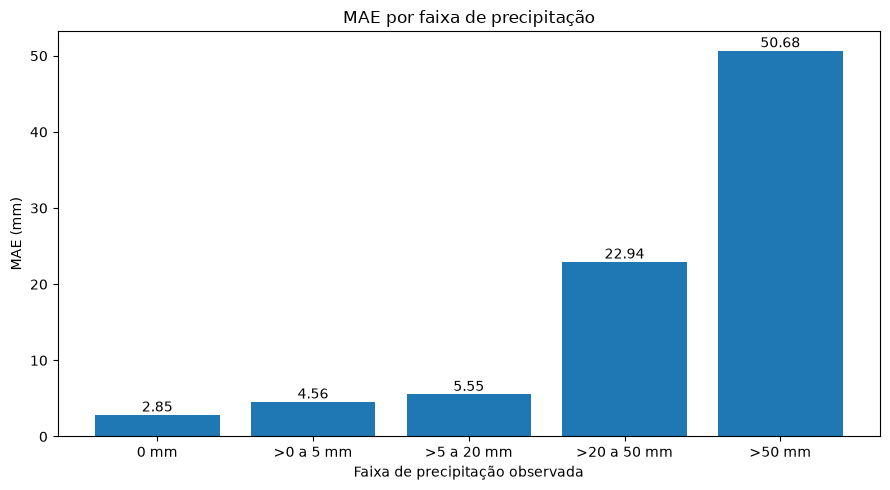

In [12]:
plt.figure(figsize=(9, 5))

barras = plt.bar(
    analise_faixas["faixa_precipitacao"].astype(str),
    analise_faixas["MAE_mm"]
)

plt.xlabel("Faixa de precipitação observada")
plt.ylabel("MAE (mm)")
plt.title("MAE por faixa de precipitação")

for barra, valor in zip(
    barras,
    analise_faixas["MAE_mm"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{valor:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

O MAE apresenta crescimento expressivo conforme aumenta a intensidade da precipitação observada.

Nos dias sem chuva e nos eventos de baixa intensidade, o erro absoluto médio permanece relativamente reduzido. Entretanto, para precipitações entre 20 e 50 mm, o MAE aumenta para **22,94 mm**, enquanto nos eventos acima de 50 mm alcança **50,68 mm**.

Esse comportamento confirma que a principal limitação do modelo está associada à previsão da magnitude dos eventos mais intensos, enquanto o desempenho é mais satisfatório nas condições de precipitação mais frequentes.

## Síntese da avaliação final

A Random Forest multivariada otimizada, selecionada na etapa de modelagem, apresentou MAE de 5,251 mm e RMSE de 9,217 mm no conjunto de teste final, composto pelos 20% mais recentes dos registros disponíveis para modelagem.

A avaliação foi realizada utilizando dados meteorológicos agregados conforme o horário civil de São Paulo (America/Sao_Paulo), respeitando as mudanças históricas do horário de verão. A base de modelagem contou com 4.953 registros, distribuídos cronologicamente entre 3.962 observações de treinamento (08/01/2010 a 11/01/2022) e 991 observações de teste (12/01/2022 a 21/12/2025).

Os erros obtidos no teste foram inferiores às médias observadas durante a validação temporal, na qual o modelo apresentou MAE médio de 5,497 mm e RMSE médio de 10,175 mm. Esses resultados indicam que o modelo manteve desempenho competitivo no período de avaliação, embora as diferenças entre as métricas possam estar relacionadas às características dos períodos analisados.

Apesar dos resultados globais, as análises gráficas e a avaliação por faixas de precipitação evidenciaram limitações importantes. O modelo apresentou tendência de superestimação em dias secos ou com baixos acumulados e, principalmente, de subestimação dos eventos de maior intensidade.

Nos eventos com precipitação observada acima de 20 mm e até 50 mm, o acumulado médio observado foi de 31,31 mm, enquanto a previsão média foi de 8,37 mm, resultando em MAE de 22,94 mm. Nos eventos acima de 50 mm, o MAE aumentou para 50,68 mm, enquanto a precipitação média observada foi de 60,92 mm e a previsão média de apenas 10,24 mm. Essa última faixa contém somente 10 observações, exigindo cautela na generalização dos resultados.

Esses resultados indicam que o modelo apresenta erros menores nas condições de precipitação mais frequentes da série, mas possui dificuldades importantes na estimativa da magnitude de eventos intensos e pouco frequentes. Dessa forma, as métricas globais devem ser interpretadas em conjunto com as análises por faixa de precipitação e com as representações gráficas dos valores observados e previstos.